# External-validation response figures

This notebook produces the two external bar charts retained in the response:
the full single-study cohort (**53 pairs**) and the subset without qualifying
direct similarity to the original equation-development data (**11 pairs**).
All study pairs are retained, including the previously excluded AlphaFold energy outlier.

Inputs use the completed matched-template run: 22 pairs were re-docked with
AlphaFold using the same observed receptor sequences as Boltz. Supplemental
scores and cross-model RMSD were refreshed; Boltz structures were retained.

Bars show absolute Pearson r; signed scores and correlations are unchanged.
The cohort contains binders only, so it does not define an AUROC benchmark.
Cached AlphaFold, supplemental and Boltz inputs are required; this notebook
does not run docking or feature extraction.


In [1]:
from pathlib import Path
import hashlib
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import sympy as sp

%matplotlib inline
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'svg.fonttype': 'none'})
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'src/binding_score_function/external_validation.py').is_file())
sys.path.insert(0, str(ROOT / 'src/binding_score_function'))
from response_plotting import PREDICTOR_COLORS, RESPONSE_WIDTH, draw_score_bars, save_figure

RUN_DIR = Path(os.environ.get('EXTERNAL_VALIDATION_RUN',
               '/srv/data1/er8813ha/bopep/external_val_matched_templates_20261113'))
FEATURES_PATH = Path(os.environ.get('EXTERNAL_VALIDATION_FEATURES', str(RUN_DIR / 'features.csv')))
ANALYSIS = Path(os.environ.get('EXTERNAL_VALIDATION_ANALYSIS', str(RUN_DIR / 'analysis')))
SUPPLEMENT = Path(os.environ.get('EXTERNAL_VALIDATION_SUPPLEMENT',
                                 str(ANALYSIS / 'supplemental_features.csv')))
BOLTZ_FEATURES = Path(os.environ.get('EXTERNAL_VALIDATION_BOLTZ_FEATURES',
                                    str(ANALYSIS / 'boltz_features.csv')))
FIGURES = ROOT / 'revision_2_bopep_working_assets'
SUPPLEMENT_INPUTS = ['alphafold_rosetta_score', 'instability_index', 'hydrophobic_aa_percent', 'uHrel']
BOLTZ_INPUTS = ['inter_model_rmsd','delta_net_charge_frac','isoelectric_point',
                'positively_charged_aa_percent','negatively_charged_aa_percent',
                'gravy','boltz_peptide_plddt','boltz_chain_0_ptm',
                'boltz_confidence_score','boltz_chain_1_ptm',
                'boltz_interface_sasa','boltz_distance_score','intra_boltz_mean_rmsd',
                'turn_fraction','boltz_iptm','boltz_peptide_pae','boltz_interface_dG',
                'boltz_complex_iplddt','boltz_ipsae_max','boltz_n_contacts']


In [2]:
raw = pd.read_csv(FEATURES_PATH)
extra = pd.read_csv(SUPPLEMENT)
boltz = pd.read_csv(BOLTZ_FEATURES)
keys = ['complex_id', 'target_id', 'peptide_sequence']

# Validate the complete cache against the same 53 study inputs.
required = set(keys + BOLTZ_INPUTS + ['boltz_status', 'features_sha256'])
missing = required.difference(boltz.columns)
if missing:
    raise ValueError(f'Boltz cache is missing columns: {sorted(missing)}')
if boltz.complex_id.duplicated().any():
    raise ValueError('Boltz cache contains duplicate complex IDs')
expected_keys = set(raw.loc[raw.study_id.eq('ASHI_2026_FP'), keys].itertuples(index=False, name=None))
cached_keys = set(boltz[keys].itertuples(index=False, name=None))
if cached_keys != expected_keys or not boltz.boltz_status.eq('complete').all():
    raise ValueError('A complete Boltz cache for the same study pairs is required')
source_hash = hashlib.sha256(FEATURES_PATH.read_bytes()).hexdigest()
if not boltz.features_sha256.eq(source_hash).all():
    raise ValueError('Boltz cache was scored from a different AlphaFold features file')
if not np.isfinite(boltz[BOLTZ_INPUTS].to_numpy(dtype=float)).all():
    raise ValueError('Boltz cache contains nonfinite scoring inputs')

required_extra = set(keys + SUPPLEMENT_INPUTS + ['features_sha256'])
if not required_extra.issubset(extra.columns):
    raise ValueError('Supplemental cache is missing required columns')
if extra.complex_id.duplicated().any():
    raise ValueError('Supplemental cache contains duplicate complex IDs')
if set(extra[keys].itertuples(index=False, name=None)) != set(raw[keys].itertuples(index=False, name=None)):
    raise ValueError('A supplemental cache for the same AlphaFold inputs is required')
if not extra.features_sha256.eq(source_hash).all():
    raise ValueError('Supplemental cache was scored from a different AlphaFold features file')
if not np.isfinite(extra[SUPPLEMENT_INPUTS].to_numpy(dtype=float)).all():
    raise ValueError('Supplemental cache contains nonfinite scoring inputs')

features = raw.merge(extra[keys + SUPPLEMENT_INPUTS],
                     on=keys, validate='one_to_one').set_index('complex_id')
features = features.loc[features.study_id.eq('ASHI_2026_FP')].copy()
features = features.reset_index().merge(boltz[keys + BOLTZ_INPUTS],
                                        on=keys, validate='one_to_one').set_index('complex_id')


In [3]:
def frozen_score(frame,version,task,equation_index):
    folder = ROOT / version / task
    equations = pd.read_csv(folder / f'symbolic_{task}_all_equations.csv').set_index('equation_index')
    expression = sp.sympify(equations.loc[equation_index,'equation'])
    names = sorted(str(symbol) for symbol in expression.free_symbols)
    source_names = [f'alphafold_{name}' if version=='plots_v1' else name for name in names]
    scaler = pd.read_csv(folder / 'scaling_params.csv',index_col=0).loc[names]
    values = frame[source_names].to_numpy(dtype=float)
    # Frozen training min/max, without refitting or clipping.
    scaled = (values-scaler['min'].to_numpy())/(scaler['max']-scaler['min']).to_numpy()
    evaluate = sp.lambdify([sp.Symbol(name) for name in names],expression,modules='numpy')
    prediction = np.broadcast_to(np.asarray(evaluate(*scaled.T),dtype=float),(len(frame),)).copy()
    return pd.Series(prediction,index=frame.index)

scores = pd.DataFrame(index=features.index)
scores['v1 R'] = frozen_score(features, 'plots_v1', 'regression', 4)
scores['v1 R×C'] = scores['v1 R'] * frozen_score(features, 'plots_v1', 'classification', 2)
for family, label, regression, classification in [
        ('alphafold', 'AlphaFold', 12, 14), ('boltz', 'Boltz', 4, 9), ('both', 'combined', 13, 8)]:
    scores[f'v2 {label} R'] = frozen_score(features, f'plots_v2_{family}', 'regression', regression)
    classifier = frozen_score(features, f'plots_v2_{family}', 'classification', classification)
    scores[f'v2 {label} R×C'] = scores[f'v2 {label} R'] * classifier

scores['ipTM'] = features.alphafold_iptm
scores['−peptide PAE'] = -features.alphafold_peptide_pae
scores['−interface ΔG'] = -features.alphafold_interface_dG
scores['default score'] = scores['ipTM'] * scores['−peptide PAE'] * scores['−interface ΔG'] * -1
scores['Boltz ipTM'] = features.boltz_iptm
scores['−Boltz peptide PAE'] = -features.boltz_peptide_pae
scores['−Boltz interface ΔG'] = -features.boltz_interface_dG
scores['Boltz default score'] = scores['Boltz ipTM'] * scores['−Boltz peptide PAE'] * scores['−Boltz interface ΔG'] * -1
if not np.isfinite(scores.to_numpy(dtype=float)).all():
    raise ValueError('Nonfinite frozen-equation predictions')


In [4]:
def plot_external_bars(frame, score_frame):
    correlations = pd.Series({name: pearsonr(frame.pKd, score_frame[name]).statistic
                              for name in score_frame})
    groups = [
        ('v1', ['v1 R', 'v1 R×C'], PREDICTOR_COLORS['v1']),
        ('AlphaFold', ['v2 AlphaFold R', 'v2 AlphaFold R×C', 'ipTM', '−peptide PAE',
                      '−interface ΔG', 'default score'], PREDICTOR_COLORS['alphafold']),
        ('Boltz', ['v2 Boltz R', 'v2 Boltz R×C', 'Boltz ipTM', '−Boltz peptide PAE',
                  '−Boltz interface ΔG', 'Boltz default score'], PREDICTOR_COLORS['boltz']),
        ('Combined', ['v2 combined R', 'v2 combined R×C'], PREDICTOR_COLORS['both']),
    ]
    fig, ax = plt.subplots(figsize=(RESPONSE_WIDTH, 1.9), layout='constrained')
    fig.set_constrained_layout_pads(w_pad=.035, h_pad=.03)
    draw_score_bars(ax, correlations, groups, 'Pearson r', 'Regression',
                    xlabel=True, score_fontsize=6.5)
    return fig, ax


## Full cohort

53 receptor–peptide pairs, including the previously excluded AlphaFold energy outlier.


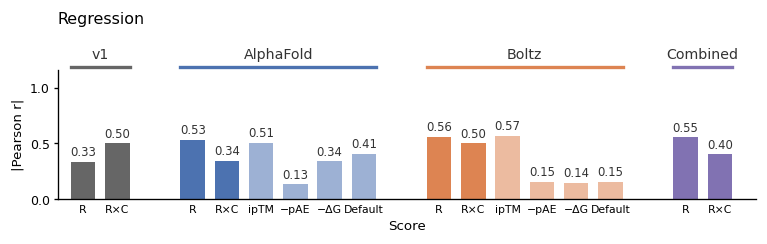

In [5]:
fig, ax = plot_external_bars(features, scores)
_ = save_figure(fig, FIGURES / 'response_external_full_bars')


## No direct development-data similarity

11 complexes after excluding qualifying receptor, peptide and PDB-source
similarity to the original training and validation data. Membership uses the
saved overlap-audit flag. The restored pair does not meet this subset's similarity criterion.


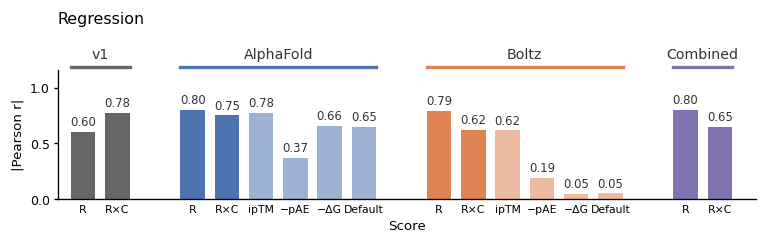

In [6]:
dissimilar_mask = features['score_original_development_no_qualifying_direct_similarity'].eq(True)
dissimilar_features = features.loc[dissimilar_mask]
dissimilar_scores = scores.loc[dissimilar_features.index]
fig, ax = plot_external_bars(dissimilar_features, dissimilar_scores)
_ = save_figure(fig, FIGURES / 'response_external_dissimilar_bars')
